# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

### Question 6 - Experimental Analysis and Interpretation

# Imports

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

seed = 2023
torch.manual_seed(seed)
np.random.seed(seed)

Device: cuda


## Check and download the dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print("Dataset directory:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

# Sanity check that the files we need are present
for f in ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]:
    path = os.path.join(DATA_DIR, f)
    print(("OK  " if os.path.exists(path) else "MISSING "), f)

/home/obaid/miniconda3/envs/dl4stg_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset directory: /home/obaid/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files: ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
OK   ca_meta.csv
OK   ca_rn_adj.npy
OK   ca_his_raw_2020.h5
OK   ca_his_raw_2021.h5


## Load data, build windows, and normalize the graph

In [3]:
# San Diego sensors (District 11)
ca_meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))
sd_meta = ca_meta[ca_meta.District == 11].reset_index(drop=True)
sd_ids = sd_meta.ID.astype(str).values.tolist()
sd_pos = sd_meta.ID2.values.tolist()
N = len(sd_meta)

# Flow 2020 + 2021, 15-min averages, filled
frames = [pd.read_hdf(os.path.join(DATA_DIR, f"ca_his_raw_{y}.h5"))[sd_ids] for y in ["2020", "2021"]]
flow = pd.concat(frames).sort_index()
flow.index = pd.to_datetime(flow.index)
flow = flow.resample("15min").mean()
# interpolate gaps, fill edges, then zero-out fully-empty sensors (no NaNs left)
flow = flow.interpolate(method="time", limit_direction="both").ffill().bfill().fillna(0.0)

A_sd = np.load(os.path.join(DATA_DIR, "ca_rn_adj.npy"))[np.ix_(sd_pos, sd_pos)]
print("Sensors:", N, "| flow:", flow.shape)

Sensors: 716 | flow: (70176, 716)


In [4]:
T_in, T_out = 8, 4
values = flow.values.astype(np.float32)
idx = flow.index

train_vals = values[(idx >= "2020-01-01") & (idx < "2021-01-01")]
val_vals   = values[(idx >= "2021-01-01") & (idx < "2021-04-01")]
test_vals  = values[(idx >= "2021-04-01") & (idx < "2022-01-01")]
mean, std = train_vals.mean(), train_vals.std()

def make_windows(arr):
    arr = (arr - mean) / std
    X, Y = [], []
    for t in range(len(arr) - T_in - T_out + 1):
        X.append(arr[t:t+T_in]); Y.append(arr[t+T_in:t+T_in+T_out])
    return torch.tensor(np.array(X)[..., None]), torch.tensor(np.array(Y)[..., None])

Xtr, Ytr = make_windows(train_vals)
Xva, Yva = make_windows(val_vals)
Xte, Yte = make_windows(test_vals)

# Graph normalizations
def sym_norm(A):
    A = A + np.eye(A.shape[0]); deg = A.sum(1)
    d = np.zeros_like(deg); nz = deg > 0; d[nz] = deg[nz] ** -0.5
    D = np.diag(d); return D @ A @ D

A_sym = torch.tensor(sym_norm(A_sd), dtype=torch.float32, device=device)
A_rn = torch.tensor(A_sd + np.eye(N), dtype=torch.float32, device=device)
A_rn = A_rn / A_rn.sum(1, keepdim=True).clamp(min=1e-8)
print("Windows:", len(Xtr), len(Xva), len(Xte))

Windows: 35125 8629 26389


## Model and training protocol

In [5]:
class TemporalEncoder(nn.Module):
    def __init__(self, hidden=32, k=3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, hidden, k, padding=k // 2)
        self.conv2 = nn.Conv1d(hidden, hidden, k, padding=k // 2)
        self.relu = nn.ReLU()
    def forward(self, x):
        B, T, N, F = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B * N, F, T)
        z = self.relu(self.conv1(x)); z = self.relu(self.conv2(z))
        return z.mean(dim=-1).reshape(B, N, -1)


class STGNN(nn.Module):
    def __init__(self, hidden=32, horizon=T_out, graph_mode="fixed", d_e=16, topk=None):
        super().__init__()
        self.mode = graph_mode; self.topk = topk
        self.register_buffer("A_sym", A_sym)
        self.register_buffer("A_rn", A_rn)
        self.temporal = TemporalEncoder(hidden)
        self.Wg = nn.Linear(hidden, hidden, bias=False)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, horizon))
        self.relu = nn.ReLU()
        if graph_mode in ("adaptive", "hybrid"):
            self.E1 = nn.Parameter(torch.randn(N, d_e) * 0.1)
            self.E2 = nn.Parameter(torch.randn(N, d_e) * 0.1)
        if graph_mode == "hybrid":
            self.raw_alpha = nn.Parameter(torch.tensor(0.0))

    def adaptive_adj(self):
        scores = self.relu(self.E1 @ self.E2.t())
        if self.topk is not None:
            vals, ix = torch.topk(scores, self.topk, dim=1)
            scores = torch.full_like(scores, float("-inf")).scatter(1, ix, vals)
        else:
            scores = scores.masked_fill(scores == 0, float("-inf"))
        return torch.softmax(scores, dim=1)

    def get_adjacency(self):
        if self.mode == "fixed":    return self.A_sym
        if self.mode == "adaptive": return self.adaptive_adj()
        a = torch.sigmoid(self.raw_alpha)
        return a * self.A_rn + (1 - a) * self.adaptive_adj()

    def forward(self, x):
        z = self.temporal(x)
        if self.mode == "none":
            h = z
        else:
            h = self.relu(self.Wg(torch.einsum("nm,bmd->bnd", self.get_adjacency(), z)))
        y = self.head(h)
        return y.permute(0, 2, 1).unsqueeze(-1)


def iterate(X, Y, bs, shuffle):
    order = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for s in range(0, len(X), bs):
        b = order[s:s+bs]
        yield X[b].to(device), Y[b].to(device)

def train_model(model, epochs=10, bs=64, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    for _ in range(epochs):
        model.train()
        for xb, yb in iterate(Xtr, Ytr, bs, True):
            opt.zero_grad(); loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()

@torch.no_grad()
def evaluate(model, X, Y, bs=64):
    model.eval(); preds, trues = [], []
    for xb, yb in iterate(X, Y, bs, False):
        preds.append(model(xb).cpu()); trues.append(yb.cpu())
    pred = torch.cat(preds) * std + mean
    true = torch.cat(trues) * std + mean
    return (pred - true).abs().mean().item(), ((pred - true) ** 2).mean().sqrt().item()

def run(graph_mode, topk=None, epochs=10):
    m = STGNN(graph_mode=graph_mode, topk=topk)
    t0 = time.perf_counter(); train_model(m, epochs); dt = time.perf_counter() - t0
    mae, rmse = evaluate(m, Xte, Yte)
    print(f"[{graph_mode:9s}] test MAE {mae:.3f}  RMSE {rmse:.3f}  time {dt:.1f}s")
    return m, mae, rmse, dt

## Train the four models

In [6]:
m_none, mae_none, rmse_none, t_none = run("none")
m_fix,  mae_fix,  rmse_fix,  t_fix  = run("fixed")
m_ada,  mae_ada,  rmse_ada,  t_ada  = run("adaptive", topk=20)
m_hyb,  mae_hyb,  rmse_hyb,  t_hyb  = run("hybrid",   topk=20)

[none     ] test MAE 21.527  RMSE 34.742  time 72.1s
[fixed    ] test MAE 48.491  RMSE 79.111  time 75.5s
[adaptive ] test MAE 26.890  RMSE 44.242  time 86.3s
[hybrid   ] test MAE 26.539  RMSE 41.781  time 104.1s


## Q6(a) - Forecasting Comparison

In [7]:
table = pd.DataFrame([
    {"Model": "Temporal-only", "Adjacency": "None",     "MAE": mae_none, "RMSE": rmse_none, "Training time (s)": t_none},
    {"Model": "STGNN",         "Adjacency": "Fixed",    "MAE": mae_fix,  "RMSE": rmse_fix,  "Training time (s)": t_fix},
    {"Model": "STGNN",         "Adjacency": "Adaptive", "MAE": mae_ada,  "RMSE": rmse_ada,  "Training time (s)": t_ada},
    {"Model": "STGNN",         "Adjacency": "Hybrid",   "MAE": mae_hyb,  "RMSE": rmse_hyb,  "Training time (s)": t_hyb},
])
print(table.to_string(index=False))
table.to_csv("results_q6.csv", index=False)

        Model Adjacency       MAE      RMSE  Training time (s)
Temporal-only      None 21.527466 34.742462          72.139427
        STGNN     Fixed 48.491119 79.111206          75.531047
        STGNN  Adaptive 26.890320 44.241806          86.260582
        STGNN    Hybrid 26.539202 41.781460         104.096114


### Predicted vs actual traffic flow (3 sensors)

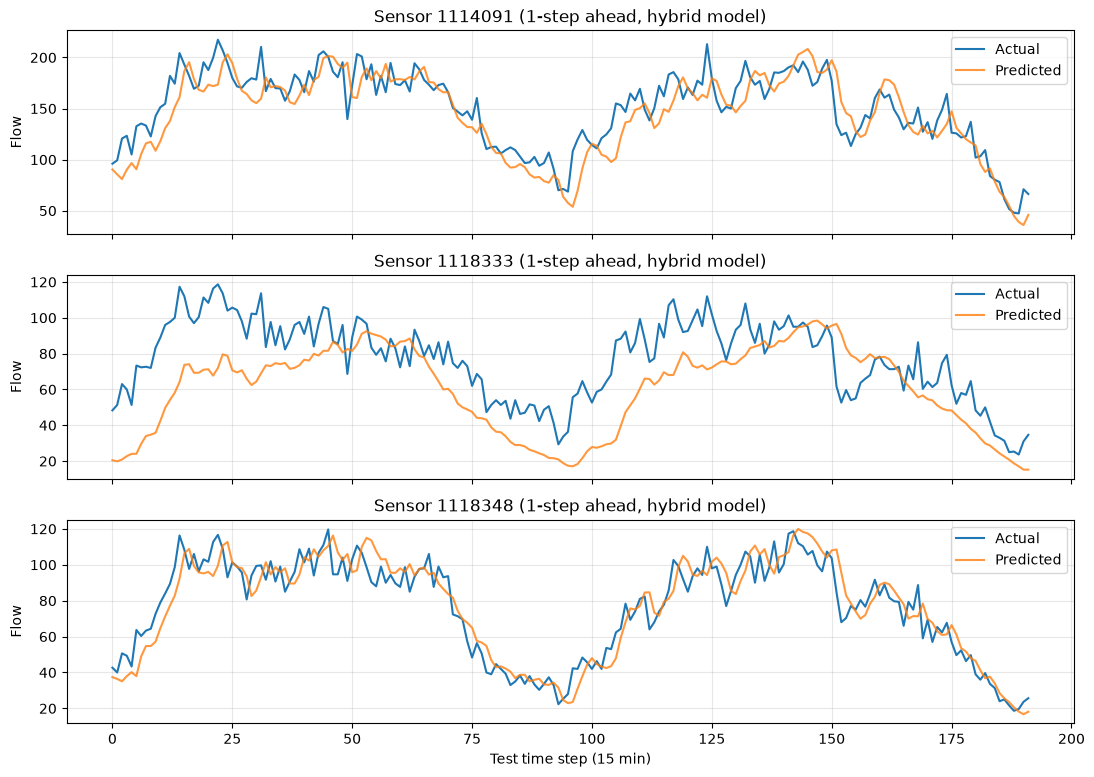

In [8]:
@torch.no_grad()
def predictions(model):
    model.eval(); preds = []
    for xb, _ in iterate(Xte, Yte, 64, False):
        preds.append(model(xb).cpu())
    return torch.cat(preds) * std + mean

pred = predictions(m_hyb)
true = Yte * std + mean

sensors = [0, 1, 2]
window = slice(0, 96 * 2)   # first two test days

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, s in zip(axes, sensors):
    ax.plot(true[window, 0, s, 0], label="Actual")
    ax.plot(pred[window, 0, s, 0], label="Predicted", alpha=0.8)
    ax.set(title=f"Sensor {sd_ids[s]} (1-step ahead, hybrid model)", ylabel="Flow")
    ax.legend(); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Test time step (15 min)")

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/q6a_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## Q6(b) - Graph Structure Analysis

In [9]:
A_learned = m_ada.get_adjacency().detach().cpu().numpy()
np.fill_diagonal(A_learned, 0)

k = 20
topk_idx = np.argsort(-A_learned, axis=1)[:, :k]     # top-k learned neighbours per node
rows = np.repeat(np.arange(N), k)
cols = topk_idx.reshape(-1)

road = (A_sd != 0)
is_road = road[rows, cols]

overlap = is_road.mean()
print(f"Top-{k} learned edges that are also road edges: {is_road.sum()} / {len(rows)}"
      f"  ({100*overlap:.1f}%)")
print(f"Learned edges NOT in the road graph: {(~is_road).sum()}  "
      f"({100*(1-overlap):.1f}%)  <- dependencies the physical graph misses")

Top-20 learned edges that are also road edges: 877 / 14320  (6.1%)
Learned edges NOT in the road graph: 13443  (93.9%)  <- dependencies the physical graph misses


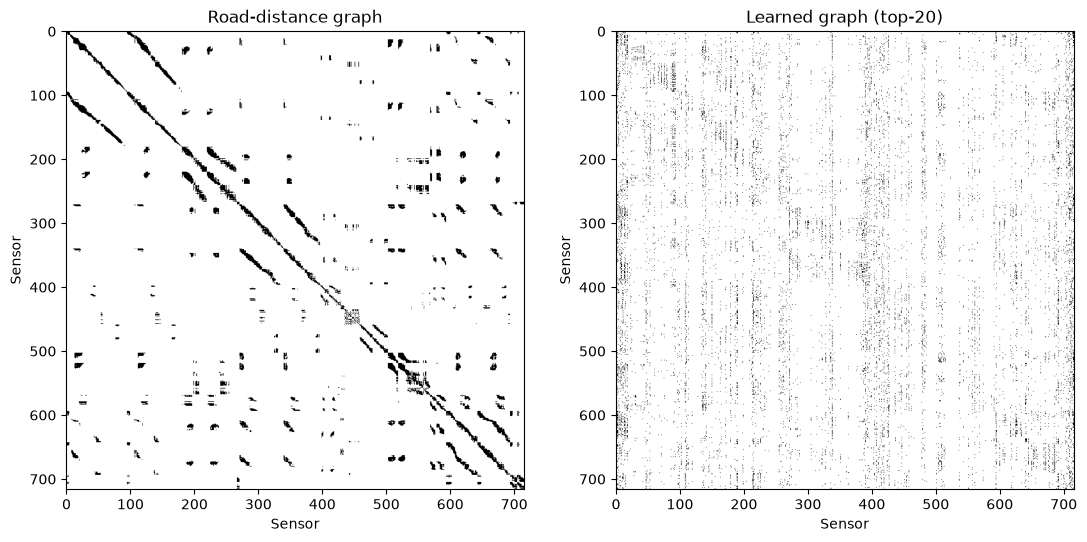

In [10]:
# Side-by-side: road graph vs learned graph (binary top-k)
learned_bin = np.zeros((N, N))
learned_bin[rows, cols] = 1

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(road, cmap="Greys"); axes[0].set(title="Road-distance graph", xlabel="Sensor", ylabel="Sensor")
axes[1].imshow(learned_bin, cmap="Greys"); axes[1].set(title=f"Learned graph (top-{k})", xlabel="Sensor", ylabel="Sensor")
fig.savefig("figures/q6b_road_vs_learned.png", dpi=150, bbox_inches="tight")
plt.show()